<a href="https://colab.research.google.com/github/varunrm/New-York-ML-project/blob/main/NYC_Taxi_Tip_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Tipping Behavior in NYC Yellow Taxi Trips
### Deliverable: Data Preprocessing and Initial Model Development

**Business problem.** Card tips are a large share of NYC taxi driver income, yet drivers and fleet operators cannot tell in advance which trips will earn a standard tip (20% or more). This notebook builds a first classification model that predicts, from trip details known when the ride ends but before the tip is entered, whether a credit-card trip will receive a tip of **at least 20%** of the pre-tip charge.

**Dataset.** NYC TLC Yellow Taxi Trip Records, January 2016 (Kaggle: elemento/nyc-yellow-taxi-trip-data, ~10.9 million trips). A seeded 10% random sample is loaded to fit within Google Colab memory.



## 1. Setup and Imports

In [1]:

import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub[pandas-datasets]'], check=False)

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 2. Data Loading

The Kaggle dataset contains four monthly CSV files (2015-01, 2016-01, 2016-02, 2016-03), each 1.7-2.0 GB. Because it has several files, `file_path` must name one of them. We load **January 2016** and use `pandas_kwargs` to keep a reproducible ~10% random sample of rows, spread across the whole month. The public dataset downloads without a Kaggle login; if Colab asks for credentials, run `kagglehub.login()` first.

*Scaling note:* for the full 10.9M rows, the same file can be read with `dask.dataframe.read_csv` (optional library listed in the brief).

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "yellow_tripdata_2016-01.csv"

# Keep the header row plus a seeded ~10% random sample of trips
SAMPLE_FRAC = 0.10
rng = np.random.default_rng(RANDOM_STATE)

start = time.time()
# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "elemento/nyc-yellow-taxi-trip-data",
  file_path,
  pandas_kwargs={
      "skiprows": lambda i: i > 0 and rng.random() > SAMPLE_FRAC,
      "parse_dates": ["tpep_pickup_datetime", "tpep_dropoff_datetime"],
  },
)
print(f"Loaded in {time.time() - start:.0f} s")
print("First 5 records:", df.head())

Using Colab cache for faster access to the 'nyc-yellow-taxi-trip-data' dataset.
Loaded in 65 s
First 5 records:    VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2  2016-01-01 00:00:00   2016-01-01 00:00:00                3   
1         1  2016-01-01 00:00:06   2016-01-01 00:04:44                1   
2         2  2016-01-01 00:00:10   2016-01-01 00:02:20                1   
3         1  2016-01-01 00:00:30   2016-01-01 00:15:47                1   
4         2  2016-01-01 00:00:44   2016-01-01 00:05:15                1   

   trip_distance  pickup_longitude  pickup_latitude  RatecodeID  \
0           1.76        -73.960625        40.781330           1   
1           1.70        -73.982101        40.774696           1   
2           0.87        -73.954407        40.778069           1   
3           5.10        -73.990585        40.745880           1   
4           1.10        -73.974159        40.795731           1   

  store_and_fwd_flag  dropoff_long

## 3. Data Exploration

In [4]:
print("Shape:", df.shape)
df.info()

Shape: (1090150, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1090150 entries, 0 to 1090149
Data columns (total 19 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   VendorID               1090150 non-null  int64         
 1   tpep_pickup_datetime   1090150 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  1090150 non-null  datetime64[ns]
 3   passenger_count        1090150 non-null  int64         
 4   trip_distance          1090150 non-null  float64       
 5   pickup_longitude       1090150 non-null  float64       
 6   pickup_latitude        1090150 non-null  float64       
 7   RatecodeID             1090150 non-null  int64         
 8   store_and_fwd_flag     1090150 non-null  object        
 9   dropoff_longitude      1090150 non-null  float64       
 10  dropoff_latitude       1090150 non-null  float64       
 11  payment_type           1090150 non-null  int64         
 12  fare_am

In [5]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
VendorID,1090150.0,1.535315,1.0,1.0,2.0,2.0,2.0,0.498751
tpep_pickup_datetime,1090150,2016-01-16 14:05:45.331862016,2016-01-01 00:00:00,2016-01-09 00:15:31,2016-01-16 05:23:38.500000,2016-01-24 08:48:57.750000128,2016-01-31 23:59:59,NaN
tpep_dropoff_datetime,1090150,2016-01-16 14:21:00.445906176,2016-01-01 00:00:00,2016-01-09 00:29:46.500000,2016-01-16 05:52:21,2016-01-24 09:02:47.750000128,2016-02-05 17:19:54,NaN
passenger_count,1090150.0,1.671634,0.0,1.0,1.0,2.0,9.0,1.326571
trip_distance,1090150.0,2.902651,0.0,1.0,1.67,3.09,282.4,3.665514
pickup_longitude,1090150.0,-72.828816,-100.822937,-73.991493,-73.9814,-73.966148,0.0,9.128955
pickup_latitude,1090150.0,40.120546,0.0,40.736359,40.753704,40.768101,42.694084,5.029099
RatecodeID,1090150.0,1.039253,1.0,1.0,1.0,1.0,99.0,0.521263
dropoff_longitude,1090150.0,-72.89778,-80.365654,-73.991074,-73.979408,-73.962036,0.0,8.854935
dropoff_latitude,1090150.0,40.159367,0.0,40.73481,40.75415,40.769608,46.140026,4.878387


In [6]:
missing = df.isna().sum()
print("Missing values per column:\n", missing[missing > 0] if missing.sum() else "None")
print("\nDuplicate rows:", df.duplicated().sum())

payment_labels = {1: 'Credit card', 2: 'Cash', 3: 'No charge', 4: 'Dispute', 5: 'Unknown', 6: 'Voided'}
print("\nPayment type share (%):")
print((df['payment_type'].map(payment_labels).value_counts(normalize=True) * 100).round(2))

Missing values per column:
 None

Duplicate rows: 0

Payment type share (%):
payment_type
Credit card    65.80
Cash           33.72
No charge       0.35
Dispute         0.13
Name: proportion, dtype: float64


In [7]:
# Count obviously invalid records before cleaning
checks = {
    'trip_distance <= 0':          (df['trip_distance'] <= 0).sum(),
    'fare_amount <= 0':            (df['fare_amount'] <= 0).sum(),
    'passenger_count == 0':        (df['passenger_count'] == 0).sum(),
    'pickup coords == 0':          ((df['pickup_latitude'] == 0) | (df['pickup_longitude'] == 0)).sum(),
    'dropoff before/at pickup':    (df['tpep_dropoff_datetime'] <= df['tpep_pickup_datetime']).sum(),
    'RatecodeID not in 1-6':       (~df['RatecodeID'].isin([1, 2, 3, 4, 5, 6])).sum(),
}
data_quality = pd.Series(checks, name='rows').to_frame()
data_quality['% of rows'] = (data_quality['rows'] / len(df) * 100).round(2)
data_quality

,rows,% of rows
trip_distance <= 0,6446,0.59
fare_amount <= 0,703,0.06
passenger_count == 0,64,0.01
pickup coords == 0,16863,1.55
dropoff before/at pickup,1157,0.11
RatecodeID not in 1-6,22,0.00


## 4. Data Cleaning

Cleaning rules (based on TLC data dictionary and plausible NYC trips):
- Remove exact duplicate rows.
- Drop rows with missing values (none expected, but kept as a safeguard instead of forward-filling, which would invent trip values).
- Keep trips lasting **1-180 minutes** and covering **0.1-100 miles**.
- Keep **fare_amount** between \$2.50 (the 2016 initial charge) and \$500, and **1-6 passengers**.
- Keep pickup and dropoff coordinates inside a **NYC bounding box** (lat 40.49-40.92, lon -74.27 to -73.68).
- Keep valid **RatecodeID** values 1-6 and average speed at or below 80 mph.

In [8]:
raw_rows = len(df)
clean = df.drop_duplicates().dropna().copy()

clean['trip_minutes'] = (clean['tpep_dropoff_datetime'] - clean['tpep_pickup_datetime']).dt.total_seconds() / 60
clean['avg_speed_mph'] = clean['trip_distance'] / (clean['trip_minutes'] / 60)

LAT, LON = (40.49, 40.92), (-74.27, -73.68)
mask = (
    clean['trip_minutes'].between(1, 180) &
    clean['trip_distance'].between(0.1, 100) &
    clean['fare_amount'].between(2.5, 500) &
    clean['passenger_count'].between(1, 6) &
    clean['RatecodeID'].isin([1, 2, 3, 4, 5, 6]) &
    clean['pickup_latitude'].between(*LAT) & clean['pickup_longitude'].between(*LON) &
    clean['dropoff_latitude'].between(*LAT) & clean['dropoff_longitude'].between(*LON) &
    (clean['avg_speed_mph'] <= 80)
)
clean = clean[mask].copy()
print(f"Rows before cleaning: {raw_rows:,}")
print(f"Rows after cleaning:  {len(clean):,}  ({len(clean)/raw_rows:.1%} kept)")

Rows before cleaning: 1,090,150
Rows after cleaning:  1,061,249  (97.3% kept)


## 5. Exploratory Data Analysis

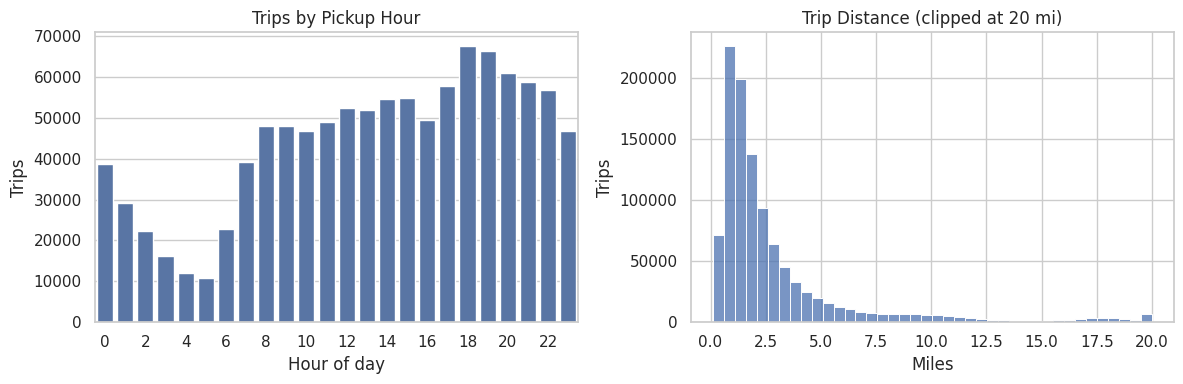

In [9]:
clean['pickup_hour'] = clean['tpep_pickup_datetime'].dt.hour
clean['pickup_dow'] = clean['tpep_pickup_datetime'].dt.dayofweek   # 0 = Monday

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=clean, x='pickup_hour', color='#4C72B0', ax=axes[0])
axes[0].set(title='Trips by Pickup Hour', xlabel='Hour of day', ylabel='Trips')
axes[0].set_xticks(range(0, 24, 2))
sns.histplot(clean['trip_distance'].clip(upper=20), bins=40, color='#4C72B0', ax=axes[1])
axes[1].set(title='Trip Distance (clipped at 20 mi)', xlabel='Miles', ylabel='Trips')
save_fig('fig1_hour_distance')

Recorded tip by payment type:
               count  mean
payment                  
Cash         355865  0.00
Credit card  701964  2.63
Dispute        1012  0.00
No charge      2408  0.00


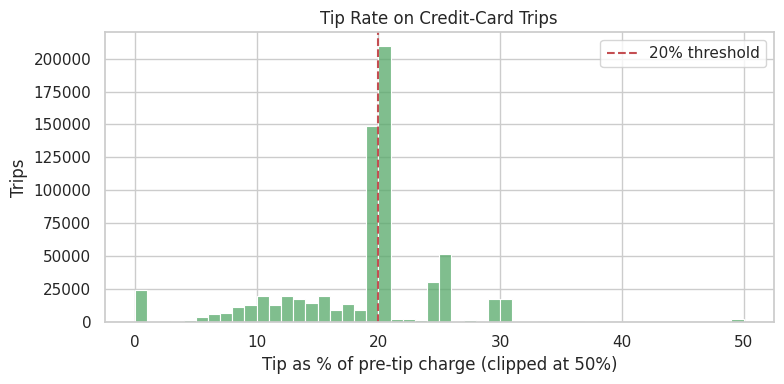

In [10]:
# Tips are only recorded electronically for card payments; cash tips show as $0
clean['pre_tip_total'] = clean['total_amount'] - clean['tip_amount']
clean['tip_rate'] = clean['tip_amount'] / clean['pre_tip_total']

tip_by_pay = (clean.assign(payment=clean['payment_type'].map(payment_labels))
                   .groupby('payment')['tip_amount'].agg(['count', 'mean']).round(2))
print("Recorded tip by payment type:\n", tip_by_pay)

card = clean[clean['payment_type'] == 1].copy()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(card['tip_rate'].clip(upper=0.5) * 100, bins=50, color='#55A868', ax=ax)
ax.axvline(20, color='#C44E52', ls='--', label='20% threshold')
ax.set(title='Tip Rate on Credit-Card Trips', xlabel='Tip as % of pre-tip charge (clipped at 50%)', ylabel='Trips')
ax.legend()
save_fig('fig2_tip_rate')

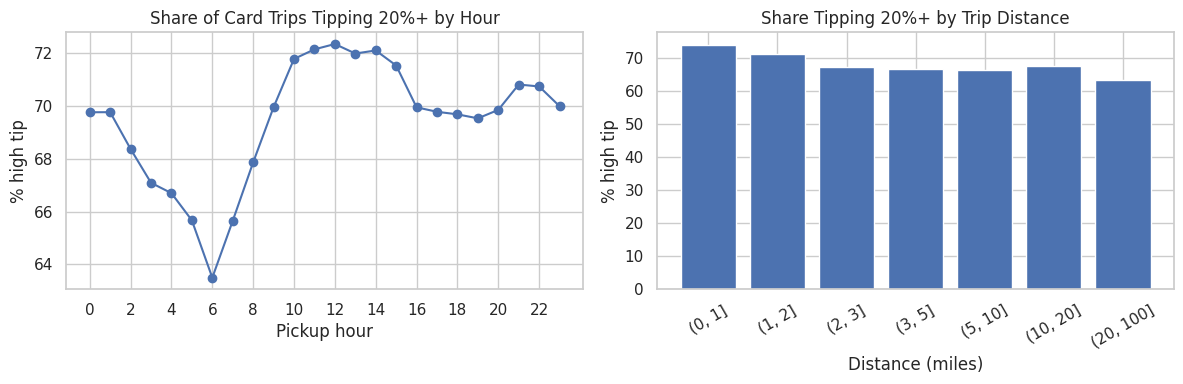

In [11]:
card['high_tip'] = (card['tip_rate'] >= 0.195).astype(int)   # 0.5-point tolerance for cent rounding

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly = card.groupby('pickup_hour')['high_tip'].mean() * 100
axes[0].plot(hourly.index, hourly.values, marker='o', color='#4C72B0')
axes[0].set(title='Share of Card Trips Tipping 20%+ by Hour', xlabel='Pickup hour', ylabel='% high tip')
axes[0].set_xticks(range(0, 24, 2))
dist_bins = pd.cut(card['trip_distance'], [0, 1, 2, 3, 5, 10, 20, 100])
by_dist = card.groupby(dist_bins, observed=True)['high_tip'].mean() * 100
axes[1].bar(by_dist.index.astype(str), by_dist.values, color='#4C72B0')
axes[1].set(title='Share Tipping 20%+ by Trip Distance', xlabel='Distance (miles)', ylabel='% high tip')
axes[1].tick_params(axis='x', rotation=30)
save_fig('fig3_hightip_hour_distance')

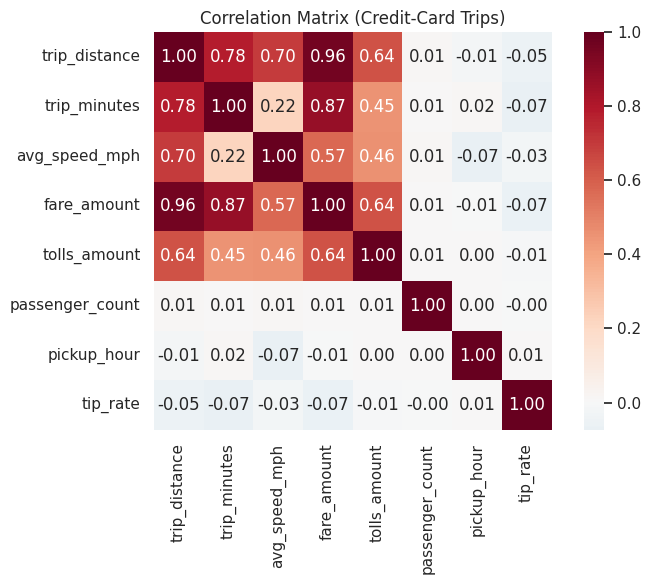

In [12]:
num_cols = ['trip_distance', 'trip_minutes', 'avg_speed_mph', 'fare_amount', 'tolls_amount',
            'passenger_count', 'pickup_hour', 'tip_rate']
plt.figure(figsize=(8, 6))
sns.heatmap(card[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation Matrix (Credit-Card Trips)')
save_fig('fig4_correlation')

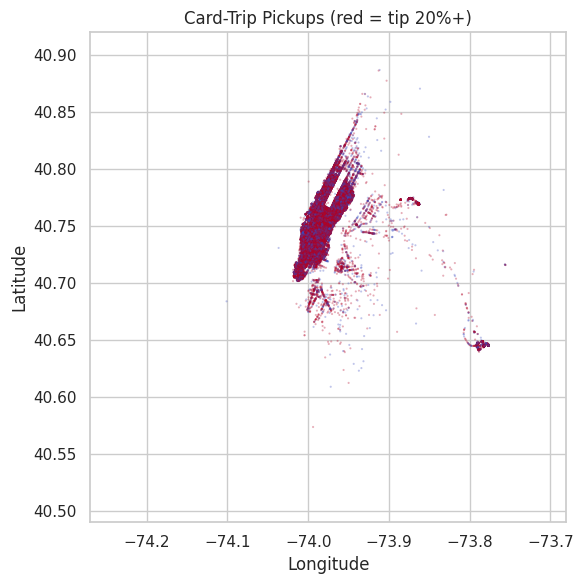

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
pts = card.sample(min(60000, len(card)), random_state=RANDOM_STATE)
ax.scatter(pts['pickup_longitude'], pts['pickup_latitude'], s=0.3, alpha=0.3, c=pts['high_tip'], cmap='coolwarm')
ax.set(title='Card-Trip Pickups (red = tip 20%+)', xlabel='Longitude', ylabel='Latitude', xlim=LON, ylim=LAT)
save_fig('fig5_pickup_map')

## 6. Feature Engineering and Target Definition

**Target:** `high_tip` = 1 if the card tip is at least 20% of the pre-tip charge, else 0.
**Scope:** credit-card trips only, because cash tips are not recorded (cash trips would all look like non-tippers and bias the model).

**Features** (all known before the tip is entered): time (hour, day of week, weekend, cyclical hour), trip (distance, duration, speed, passengers), fare items (fare, tolls, extra), location (pickup/dropoff coordinates, airport flag, Manhattan-core flag), and one-hot encoded categories (VendorID, RatecodeID, store_and_fwd_flag). `tip_amount` and `total_amount` are excluded to avoid **target leakage**.

Modeling rows: 701964 | features: 25
Class balance (%):
 high_tip
1    69.99
0    30.01
Name: proportion, dtype: float64


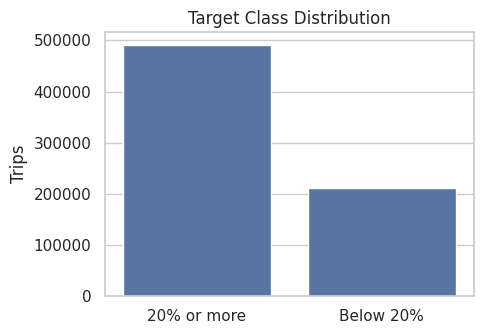

In [14]:
JFK = (40.6413, -73.7781); LGA = (40.7769, -73.8740)
def near(lat, lon, pt, r=0.02):
    return ((lat - pt[0])**2 + (lon - pt[1])**2) < r**2

feat = card.copy()
feat['is_weekend'] = (feat['pickup_dow'] >= 5).astype(int)
feat['hour_sin'] = np.sin(2 * np.pi * feat['pickup_hour'] / 24)
feat['hour_cos'] = np.cos(2 * np.pi * feat['pickup_hour'] / 24)
feat['airport_trip'] = (
    feat['RatecodeID'].isin([2, 3]) |
    near(feat['pickup_latitude'], feat['pickup_longitude'], JFK) |
    near(feat['pickup_latitude'], feat['pickup_longitude'], LGA) |
    near(feat['dropoff_latitude'], feat['dropoff_longitude'], JFK) |
    near(feat['dropoff_latitude'], feat['dropoff_longitude'], LGA)
).astype(int)
# Rough Manhattan-core box (Battery to 110th St)
feat['manhattan_pickup'] = (feat['pickup_latitude'].between(40.70, 40.80) &
                            feat['pickup_longitude'].between(-74.02, -73.93)).astype(int)

numeric = ['trip_distance', 'trip_minutes', 'avg_speed_mph', 'fare_amount', 'extra', 'tolls_amount',
           'passenger_count', 'pickup_hour', 'pickup_dow', 'is_weekend', 'hour_sin', 'hour_cos',
           'pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude',
           'airport_trip', 'manhattan_pickup']
categorical = ['VendorID', 'RatecodeID', 'store_and_fwd_flag']

model_df = pd.get_dummies(feat[numeric + categorical + ['high_tip']],
                          columns=categorical, drop_first=True, dtype=int)
X = model_df.drop(columns='high_tip')
y = model_df['high_tip']
print("Modeling rows:", X.shape[0], "| features:", X.shape[1])
print("Class balance (%):\n", (y.value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 3.5))
sns.countplot(x=y.map({0: 'Below 20%', 1: '20% or more'}), color='#4C72B0')
plt.title('Target Class Distribution'); plt.xlabel(''); plt.ylabel('Trips')
save_fig('fig6_class_balance')

## 7. Train-Test Split and Scaling

A stratified 75/25 split keeps the class ratio equal in both sets. The `StandardScaler` is **fit on the training set only** and then applied to the test set, so no test information leaks into training.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (526473, 25) | Test: (175491, 25)


## 8. Initial Model Development

Three models are compared:
1. **Baseline** - always predicts the majority class (the bar any model must beat).
2. **Logistic Regression** - linear, interpretable; `class_weight='balanced'` offsets the class imbalance.
3. **Random Forest** - non-linear ensemble that captures interactions (e.g., hour x location).

Because classes are imbalanced, we report **ROC-AUC** and **macro F1** alongside accuracy.

In [16]:
def evaluate(name, model, Xte, yte):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {
        'model': name,
        'accuracy': accuracy_score(yte, pred),
        'precision_low_tip': precision_score(yte, pred, pos_label=0, zero_division=0),
        'recall_low_tip': recall_score(yte, pred, pos_label=0, zero_division=0),
        'f1_macro': f1_score(yte, pred, average='macro'),
        'roc_auc': roc_auc_score(yte, proba),
    }

results, models = [], {}

baseline = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
models['Baseline (majority)'] = baseline
results.append(evaluate('Baseline (majority)', baseline, X_test_s, y_test))

t = time.time()
logreg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
logreg.fit(X_train_s, y_train)
models['Logistic Regression'] = logreg
results.append(evaluate('Logistic Regression', logreg, X_test_s, y_test))
print(f"Logistic Regression trained in {time.time()-t:.1f} s")

t = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=5,
                            class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train_s, y_train)
models['Random Forest'] = rf
results.append(evaluate('Random Forest', rf, X_test_s, y_test))
print(f"Random Forest trained in {time.time()-t:.1f} s")

results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

Logistic Regression trained in 3.0 s
Random Forest trained in 192.7 s


,accuracy,precision_low_tip,recall_low_tip,f1_macro,roc_auc
model,,,,,
Baseline (majority),0.700,0.000,0.000,0.412,0.500
Logistic Regression,0.562,0.341,0.493,0.529,0.558
Random Forest,0.625,0.369,0.353,0.548,0.578


In [17]:
for name in ['Logistic Regression', 'Random Forest']:
    print(f"=== {name} ===")
    print(classification_report(y_test, models[name].predict(X_test_s),
                                target_names=['Below 20%', '20% or more'], digits=3))

=== Logistic Regression ===
              precision    recall  f1-score   support

   Below 20%      0.341     0.493     0.404     52658
 20% or more      0.732     0.592     0.654    122833

    accuracy                          0.562    175491
   macro avg      0.536     0.543     0.529    175491
weighted avg      0.614     0.562     0.579    175491

=== Random Forest ===
              precision    recall  f1-score   support

   Below 20%      0.369     0.353     0.361     52658
 20% or more      0.728     0.741     0.734    122833

    accuracy                          0.625    175491
   macro avg      0.548     0.547     0.548    175491
weighted avg      0.620     0.625     0.622    175491



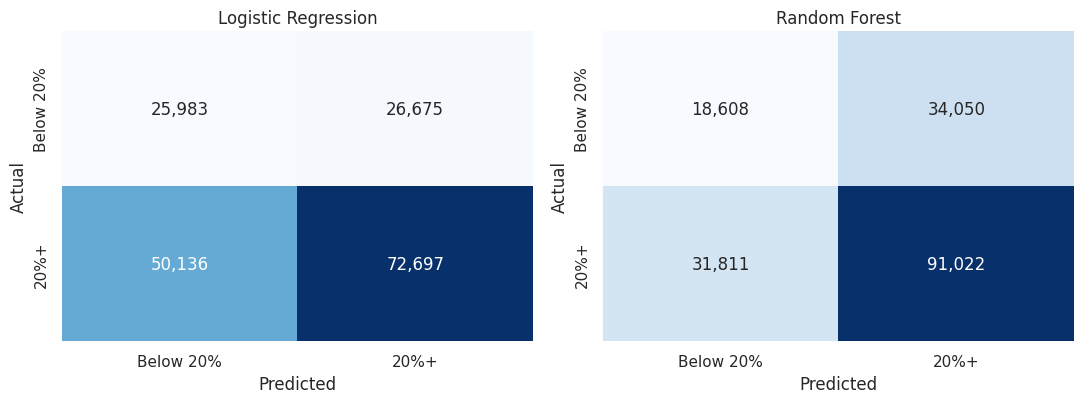

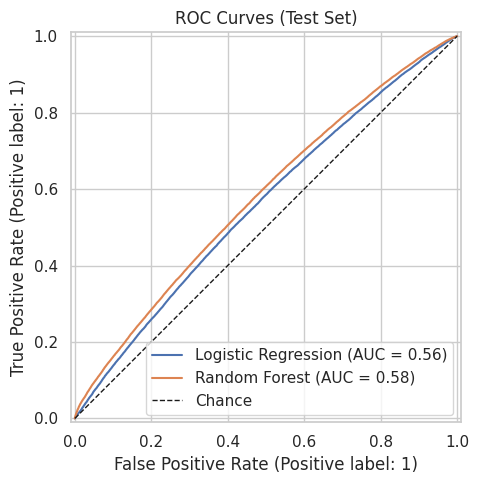

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, models[name].predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Below 20%', '20%+'], yticklabels=['Below 20%', '20%+'])
    ax.set(title=f'{name}', xlabel='Predicted', ylabel='Actual')
save_fig('fig7_confusion_matrices')

fig, ax = plt.subplots(figsize=(6, 5))
for name in ['Logistic Regression', 'Random Forest']:
    RocCurveDisplay.from_estimator(models[name], X_test_s, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax.set_title('ROC Curves (Test Set)'); ax.legend(loc='lower right')
save_fig('fig8_roc_curves')

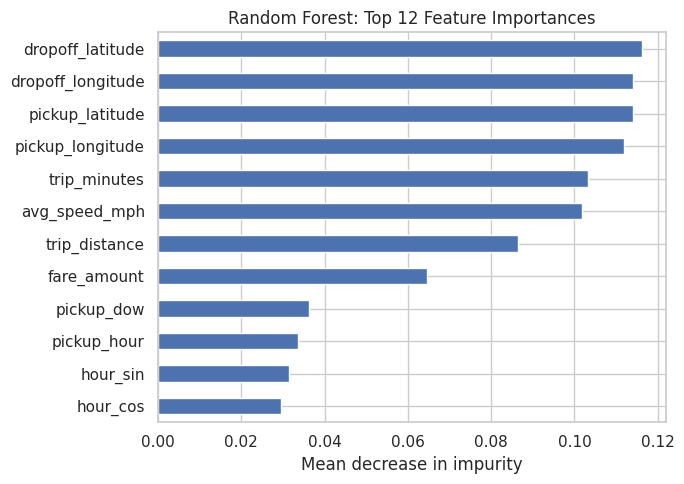

Logistic Regression - strongest negative (push toward low tip):
 fare_amount        -0.251
pickup_longitude   -0.091
hour_sin           -0.068
trip_minutes       -0.048
avg_speed_mph      -0.047
dtype: float64

Strongest positive (push toward 20%+ tip):
 pickup_dow       0.007
tolls_amount     0.033
VendorID_2       0.058
trip_distance    0.094
airport_trip     0.214
dtype: float64


In [19]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
importances.head(12)[::-1].plot.barh(color='#4C72B0')
plt.title('Random Forest: Top 12 Feature Importances'); plt.xlabel('Mean decrease in impurity')
save_fig('fig9_feature_importance')

coefs = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
print("Logistic Regression - strongest negative (push toward low tip):\n", coefs.head(5).round(3))
print("\nStrongest positive (push toward 20%+ tip):\n", coefs.tail(5).round(3))

## 9. Hyperparameter Tuning (GridSearchCV)

A grid search with 3-fold cross-validation tunes the Random Forest. To keep run time reasonable in Colab, the search uses a stratified 60,000-row subset of the training data; the best settings are then refit on the full training set. Scoring uses ROC-AUC because it is not distorted by the class imbalance.

In [20]:
X_grid, _, y_grid, _ = train_test_split(X_train_s, y_train, train_size=60000,
                                        stratify=y_train, random_state=RANDOM_STATE)
param_grid = {'n_estimators': [100, 200], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5]}

t = time.time()
grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
                    param_grid, cv=3, scoring='roc_auc', n_jobs=1)
grid.fit(X_grid, y_grid)
print(f"Grid search finished in {time.time()-t:.0f} s")
print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

cv_table = (pd.DataFrame(grid.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
              .sort_values('mean_test_score', ascending=False).round(4))
cv_table.head(6)

Grid search finished in 612 s
Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV ROC-AUC: 0.568


,params,mean_test_score,std_test_score
3,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.5675,0.0029
2,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.5664,0.0024
1,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.5658,0.0036
0,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.5649,0.0033
7,"{'max_depth': 20, 'min_samples_leaf': 5, 'n_es...",0.5617,0.0040
11,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.5615,0.0052


In [21]:
rf_tuned = RandomForestClassifier(**grid.best_params_, class_weight='balanced',
                                  n_jobs=-1, random_state=RANDOM_STATE)
rf_tuned.fit(X_train_s, y_train)
models['Random Forest (tuned)'] = rf_tuned
results.append(evaluate('Random Forest (tuned)', rf_tuned, X_test_s, y_test))
results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,accuracy,precision_low_tip,recall_low_tip,f1_macro,roc_auc
model,,,,,
Baseline (majority),0.700,0.000,0.000,0.412,0.500
Logistic Regression,0.562,0.341,0.493,0.529,0.558
Random Forest,0.625,0.369,0.353,0.548,0.578
Random Forest (tuned),0.555,0.347,0.549,0.531,0.578


## 10. Subgroup Check and Ethical Considerations

The data has no rider demographics, but performance can still differ across **trip contexts** that relate to neighborhoods and rider types. We compare tuned-model results across pickup area, airport trips, and weekday/weekend.

In [22]:
best = rf_tuned
test_meta = feat.loc[X_test.index, ['manhattan_pickup', 'airport_trip', 'is_weekend']]
pred = best.predict(X_test_s); proba = best.predict_proba(X_test_s)[:, 1]

rows = []
for col, labels in [('manhattan_pickup', {1: 'Manhattan core pickup', 0: 'Outside Manhattan core'}),
                    ('airport_trip', {1: 'Airport trip', 0: 'Non-airport trip'}),
                    ('is_weekend', {0: 'Weekday', 1: 'Weekend'})]:
    for val, label in labels.items():
        m = (test_meta[col] == val).values
        rows.append({'group': label, 'n_test': int(m.sum()),
                     'actual_high_tip_%': round(y_test[m].mean() * 100, 1),
                     'accuracy': round(accuracy_score(y_test[m], pred[m]), 3),
                     'roc_auc': round(roc_auc_score(y_test[m], proba[m]), 3)})
subgroups = pd.DataFrame(rows)
subgroups

,group,n_test,actual_high_tip_%,accuracy,roc_auc
0,Manhattan core pickup,161507,70.2,0.556,0.575
1,Outside Manhattan core,13984,67.9,0.544,0.603
2,Airport trip,12481,70.7,0.578,0.596
3,Non-airport trip,163010,69.9,0.553,0.576
4,Weekday,125452,70.2,0.560,0.580
5,Weekend,50039,69.5,0.544,0.571


### Ethical Considerations
- **What potential biases exist in the dataset?** Only card tips are recorded, so cash riders (about one-third of trips, likely skewed toward lower-income riders and outer boroughs) are invisible to the model. Card trips are also concentrated in Manhattan, so the model learns mostly Manhattan patterns.
- **How would the model perform across different groups?** No demographic fields exist, but location acts as a proxy for neighborhood income and race. The subgroup table shows how accuracy and AUC shift between Manhattan and other areas; any use that steers drivers away from low-predicted-tip areas could reduce service to already under-served neighborhoods (a known equity concern for taxi service).
- **Is the model interpretable and fair?** Logistic Regression coefficients and Random Forest importances explain which trip features drive predictions. The model should support driver earnings insight and pricing research, **not** trip refusal, which is illegal for NYC medallion taxis.
- **Is user data protected?** The data is public and de-identified, but exact GPS points with timestamps can re-identify individual trips; outputs should be aggregated (e.g., by zone and hour) before sharing.

## 11. Team Collaboration and Version Control
- Notebook is shared in **Google Colab**; each member works on a copy and saves to the team **GitHub** repo (`File > Save a copy in GitHub`).
- Branch per task (`eda`, `cleaning`, `modeling`), pull requests reviewed by one teammate before merging to `main`.
- `RANDOM_STATE = 42` and a fixed sample make all results reproducible across team members.

In [23]:
# Save key results so the written report can cite exact numbers
summary = {
    'raw_rows_sampled': int(raw_rows), 'clean_rows': int(len(clean)), 'card_rows': int(len(card)),
    'n_features': int(X.shape[1]), 'train_rows': int(len(X_train)), 'test_rows': int(len(X_test)),
    'high_tip_share': float(y.mean()), 'payment_share': clean['payment_type'].value_counts(normalize=True).round(4).to_dict(),
    'data_quality': data_quality['rows'].astype(int).to_dict(),
    'results': results_df.reset_index().to_dict(orient='records'),
    'best_params': grid.best_params_, 'best_cv_auc': float(grid.best_score_),
    'top_features': importances.head(10).round(4).to_dict(),
    'logreg_top_pos': coefs.tail(5).round(3).to_dict(), 'logreg_top_neg': coefs.head(5).round(3).to_dict(),
    'subgroups': subgroups.to_dict(orient='records'),
    'hourly_high_tip': hourly.round(1).to_dict(), 'by_distance_high_tip': {str(k): round(v, 1) for k, v in by_dist.items()},
    'tip_by_payment': tip_by_pay.reset_index().to_dict(orient='records'),
    'describe': clean[['trip_distance', 'trip_minutes', 'fare_amount', 'tip_amount', 'passenger_count']].describe().round(2).to_dict(),
}
with open('results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary['results'], indent=2))

[
  {
    "model": "Baseline (majority)",
    "accuracy": 0.7,
    "precision_low_tip": 0.0,
    "recall_low_tip": 0.0,
    "f1_macro": 0.412,
    "roc_auc": 0.5
  },
  {
    "model": "Logistic Regression",
    "accuracy": 0.562,
    "precision_low_tip": 0.341,
    "recall_low_tip": 0.493,
    "f1_macro": 0.529,
    "roc_auc": 0.558
  },
  {
    "model": "Random Forest",
    "accuracy": 0.625,
    "precision_low_tip": 0.369,
    "recall_low_tip": 0.353,
    "f1_macro": 0.548,
    "roc_auc": 0.578
  },
  {
    "model": "Random Forest (tuned)",
    "accuracy": 0.555,
    "precision_low_tip": 0.347,
    "recall_low_tip": 0.549,
    "f1_macro": 0.531,
    "roc_auc": 0.578
  }
]
